# Preprocessing E - Phase, Stateful EMA, and Temporal Context for V10

V10 adds stable inter-antenna phase differences, causal EMA magnitude residuals, and the immediately previous signal frame. It uses the V7-V9 split so results remain comparable. Previous predicted coordinates are not fed back because training with ground truth would cause teacher-forcing leakage and inference errors would accumulate.

## 1. Setup and fixed split

In [1]:
%matplotlib inline
import getpass, importlib, json, os, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from huggingface_hub import HfApi, hf_hub_download

SRC_DIR = Path.cwd() / 'src' if (Path.cwd() / 'src').exists() else Path.cwd()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import preprocessing as preprocessing_module
preprocessing_module = importlib.reload(preprocessing_module)
from preprocessing import (
    PreprocessingConfig, normalize_per_radar_channel,
    per_radar_channel_moments, transform_phase_ema_temporal,
)
HF_TOKEN = os.getenv('HF_TOKEN') or getpass.getpass('Enter your Hugging Face read-only token: ')
HF_TOKEN = HF_TOKEN.strip()
print('Authenticated as:', HfApi(token=HF_TOKEN).whoami()['name'])
ARTIFACT_DIR = SRC_DIR / 'artifacts'
with (ARTIFACT_DIR / 'data_split_v7.json').open(encoding='utf-8') as handle:
    split = json.load(handle)
V10_TRAIN_WINDOWS = split['train_windows']
V10_VALIDATION_WINDOWS = split['validation_windows']
assert V10_VALIDATION_WINDOWS == [22, 16, 2, 15, 7]
REPO_ID, CHUNK_SIZE = 'HAEEAI/multi-person-localization', 256
window_paths = {
    index: Path(hf_hub_download(
        repo_id=REPO_ID, repo_type='dataset',
        filename=f'data/window_{index:06d}.npz', token=HF_TOKEN
    ))
    for index in sorted(V10_TRAIN_WINDOWS + V10_VALIDATION_WINDOWS)
}
print(f'{len(window_paths)} cached windows are ready.')

c:\Users\213053\OneDrive\Documenti\EEAI\.venv_tf\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Authenticated as: KetrinMehmeti
24 cached windows are ready.


## 2. Representation and causal-state validation

Each frame contains 18 base channels: 3 log magnitudes, 3 EMA residuals, 6 signed I/Q values, and sine/cosine phase differences for antenna pairs 0-1, 1-2, and 0-2. Current and previous base features are concatenated into 36 channels. Sine/cosine avoids the discontinuity of raw phase angles. Original magnitude is retained so the EMA cannot erase stationary people.

In [2]:
V10_CONFIG = PreprocessingConfig(
    radar_indices=(0, 1, 2, 3, 4, 5), antenna_mode='none',
    range_bin_start=0, range_bin_stop=120, log_compression=True,
    background_mode='ema', ema_alpha=0.98,
)
BASE_CHANNEL_ORDER = [
    'A0-mag', 'A1-mag', 'A2-mag',
    'A0-ema-residual', 'A1-ema-residual', 'A2-ema-residual',
    'A0-I', 'A0-Q', 'A1-I', 'A1-Q', 'A2-I', 'A2-Q',
    'cos-dphi-01', 'sin-dphi-01', 'cos-dphi-12',
    'sin-dphi-12', 'cos-dphi-02', 'sin-dphi-02',
]
V10_CHANNEL_ORDER = [
    *(f'current-{name}' for name in BASE_CHANNEL_ORDER),
    *(f'previous-{name}' for name in BASE_CHANNEL_ORDER),
]
with np.load(window_paths[V10_TRAIN_WINDOWS[0]], allow_pickle=False) as data:
    raw = data['radar_cir_iq'][:2 * CHUNK_SIZE]
whole, _, _ = transform_phase_ema_temporal(raw, V10_CONFIG)
first, ema_state, previous_state = transform_phase_ema_temporal(raw[:CHUNK_SIZE], V10_CONFIG)
second, _, _ = transform_phase_ema_temporal(
    raw[CHUNK_SIZE:], V10_CONFIG, ema_state, previous_state
)
chunked = np.concatenate((first, second))
print('Feature shape:', whole.shape)
print('Maximum chunk-continuity difference:', float(np.max(np.abs(whole - chunked))))
assert whole.shape == (2 * CHUNK_SIZE, 6, 36, 120)
assert np.allclose(whole, chunked, atol=1e-6)

Feature shape: (512, 6, 36, 120)
Maximum chunk-continuity difference: 0.0


## 3. Leakage-free training statistics

EMA and previous-frame state continue across chunks and reset only at acquisition boundaries. Validation windows never contribute to normalisation statistics.

In [3]:
def v10_training_feature_blocks():
    for position, index in enumerate(V10_TRAIN_WINDOWS, start=1):
        print(f'[{position:02d}/{len(V10_TRAIN_WINDOWS):02d}] Window {index:06d}')
        ema_state, previous_state = None, None
        with np.load(window_paths[index], allow_pickle=False) as data:
            radar = data['radar_cir_iq']
            for start in range(0, len(radar), CHUNK_SIZE):
                features, ema_state, previous_state = transform_phase_ema_temporal(
                    radar[start:start + CHUNK_SIZE], V10_CONFIG,
                    ema_state, previous_state,
                )
                yield features

V10_MEAN, V10_STD, V10_VALUES_PER_CHANNEL = per_radar_channel_moments(
    v10_training_feature_blocks()
)
assert V10_MEAN.shape == V10_STD.shape == (6, 36)
assert np.all(V10_STD > 0)
print('Statistics shape:', V10_MEAN.shape)
print('Standard-deviation range:', float(V10_STD.min()), float(V10_STD.max()))

[01/19] Window 000000
[02/19] Window 000001
[03/19] Window 000003
[04/19] Window 000004
[05/19] Window 000005
[06/19] Window 000006
[07/19] Window 000008
[08/19] Window 000009
[09/19] Window 000010
[10/19] Window 000011
[11/19] Window 000012
[12/19] Window 000013
[13/19] Window 000014
[14/19] Window 000017
[15/19] Window 000018
[16/19] Window 000019
[17/19] Window 000020
[18/19] Window 000021
[19/19] Window 000023
Statistics shape: (6, 36)
Standard-deviation range: 0.10186190903186798 5.646330833435059


## 4. Validation diagnostics

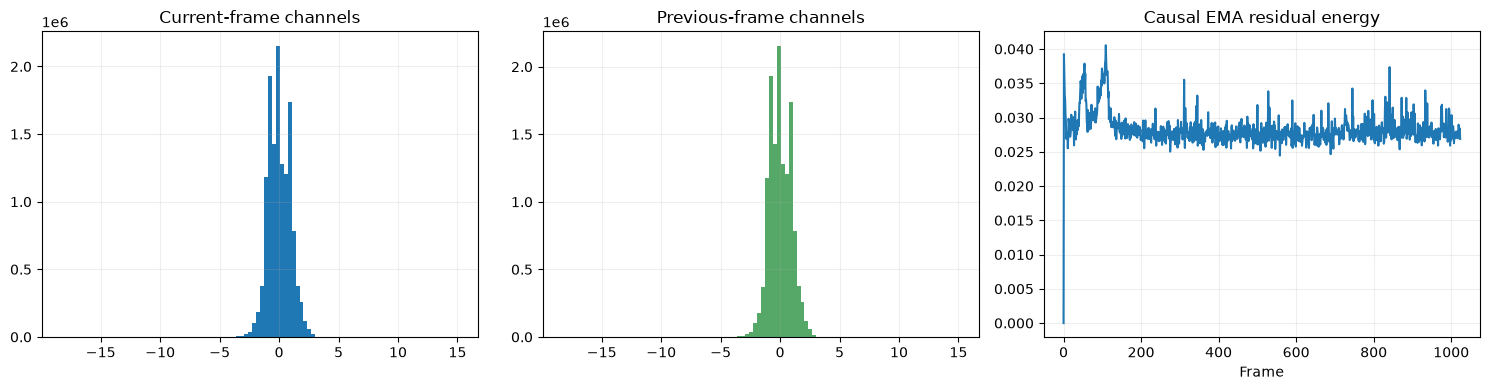

Validation finite: True


In [4]:
with np.load(window_paths[V10_VALIDATION_WINDOWS[0]], allow_pickle=False) as data:
    validation_features, _, _ = transform_phase_ema_temporal(
        data['radar_cir_iq'][:1024], V10_CONFIG
    )
validation_normalized = normalize_per_radar_channel(
    validation_features, V10_MEAN, V10_STD, V10_CONFIG.epsilon
)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(validation_normalized[:, :, :18].ravel(), bins=100)
axes[0].set(title='Current-frame channels')
axes[1].hist(validation_normalized[:, :, 18:].ravel(), bins=100, color='#55a868')
axes[1].set(title='Previous-frame channels')
axes[2].plot(np.mean(np.abs(validation_features[:, :, 3:6]), axis=(1, 2, 3)))
axes[2].set(title='Causal EMA residual energy', xlabel='Frame')
for axis in axes:
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Validation finite:', bool(np.isfinite(validation_normalized).all()))

## 5. Save V10 contract and conclusions

In [5]:
artifact = {
    'representation': 'phase_ema_previous_frame',
    'config': {
        'radar_indices': list(V10_CONFIG.radar_indices),
        'antenna_mode': V10_CONFIG.antenna_mode,
        'range_bin_start': V10_CONFIG.range_bin_start,
        'range_bin_stop': V10_CONFIG.range_bin_stop,
        'log_compression': V10_CONFIG.log_compression,
        'background_mode': V10_CONFIG.background_mode,
        'ema_alpha': V10_CONFIG.ema_alpha,
        'epsilon': V10_CONFIG.epsilon,
    },
    'base_channel_order': BASE_CHANNEL_ORDER,
    'channel_order': V10_CHANNEL_ORDER,
    'input_shape': [6, 36, 120],
    'phase_encoding': 'normalised complex cross-product sine/cosine',
    'temporal_context': 'current and immediately previous signal frame',
    'state_reset': 'once per acquisition window',
    'mean': V10_MEAN.tolist(), 'std': V10_STD.tolist(),
    'training_windows': V10_TRAIN_WINDOWS,
    'validation_windows': V10_VALIDATION_WINDOWS,
}
output_path = ARTIFACT_DIR / 'v10_phase_ema_temporal_normalization.json'
with output_path.open('w', encoding='utf-8') as handle:
    json.dump(artifact, handle, indent=2)
print('Saved:', output_path.resolve())

Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\v10_phase_ema_temporal_normalization.json


## 6. Technical implications

V10 remains feed-forward and causal. Deployment retains one EMA background tensor and one 18-channel previous-frame tensor. The model contains no LSTM, GRU, RNN, custom, or Flex operation. Phase uses multiplication, addition, division, and clipping in preprocessing rather than an angle operator. Full INT8 model size, operator compatibility, and the activation arena must still be measured after conversion.